# LeNET and It's variations

In [ ]:
import tensorflow as tf
from keras import layers, models
from keras.datasets.fashion_mnist import load_data

In [4]:
(x_train, y_train), (x_test, y_test) = load_data()
x_train = x_train[..., None].astype("float32") / 255.0     # (60000, 28, 28, 1)
x_test  = x_test[..., None].astype("float32") / 255.0

x_train.shape, y_train.shape

((60000, 28, 28, 1), (60000,))

# LeNET By Yann LeCun in 1998
- `Tanh` activation

In [ ]:
model = models.Sequential([
    layers.Input((28, 28, 1)),
    layers.Conv2D(6, 5, padding="valid", activation="tanh"),    # C1 -> 24x48x6
    layers.AveragePooling2D(2, strides=(2,2), padding='valid'), # S2 -> 12x12x6
    layers.Conv2D(16, 5, padding="valid", activation="tanh"),   # C3 -> 8x8x16
    layers.AveragePooling2D(2, strides=(2,2), padding='valid'), # S4 -> 4x4x16
    layers.Flatten(),                                           # 256
    layers.Dense(120, activation="tanh"),                       # C5 (as dense)
    layers.Dense(84, activation="tanh"),                        # F6
    layers.Dense(10, activation="softmax"),                     # output
])

model.summary()   

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
lenet_history = model.fit(x_train, y_train, epochs=10, batch_size=128, validation_split=0.1)
lenet_loss, lenet_accuracy = model.evaluate(x_test, y_test)
print(f"\n Loss = {lenet_loss}     |     Accuracy = {lenet_accuracy}")

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_24 (Conv2D)              │ (None, 24, 24, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_12            │ (None, 12, 12, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 8, 8, 16)       │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_13            │ (None, 4, 4, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_11 (Flatten)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 120)            │        30,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_36 (Dense)                │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_37 (Dense)                │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,426 (173.54 KB)

 Trainable params: 44,426 (173.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 11s 17ms/step - accuracy: 0.7444 - loss: 0.6943 - val_accuracy: 0.8130 - val_loss: 0.4974
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - accuracy: 0.8272 - loss: 0.4733 - val_accuracy: 0.8365 - val_loss: 0.4460
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.8489 - loss: 0.4155 - val_accuracy: 0.8503 - val_loss: 0.4008
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.8605 - loss: 0.3840 - val_accuracy: 0.8558 - val_loss: 0.3885
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.8692 - loss: 0.3587 - val_accuracy: 0.8660 - val_loss: 0.3625
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.8758 - loss: 0.3389 - val_accuracy: 0.8640 - val_loss: 0.3665
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.8813 - loss: 0.3233 - val_accuracy: 0.8677 - val_loss: 0.3478
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.8845 - loss: 0.3116 - val_acc

# Tanh -> ReLU activation

In [ ]:
model_relu = models.Sequential([
    layers.Input((28, 28, 1)),
    layers.Conv2D(6, 5, padding="valid", activation="relu"),    # C1 -> 24x24x6
    layers.AveragePooling2D(2, strides=(2,2), padding='valid'), # S2 -> 12x12x6
    layers.Conv2D(16, 5, padding="valid", activation="relu"),   # C3 -> 8x8x16
    layers.AveragePooling2D(2, strides=(2,2), padding='valid'), # S4 -> 4x4x16
    layers.Flatten(),                                           # 256
    layers.Dense(120, activation="relu"),                       # C5 (as dense)
    layers.Dense(84, activation="relu"),                        # F6
    layers.Dense(10, activation="softmax"),                     # output
])

model_relu.summary()

model_relu.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
relu_history = model_relu.fit(x_train, y_train, epochs=10, batch_size=128, validation_split=0.1)
relu_loss, relu_accuracy = model_relu.evaluate(x_test, y_test)

print(f"\n Loss = {relu_loss}     |     Accuracy = {relu_accuracy}")

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_28 (Conv2D)              │ (None, 24, 24, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_16            │ (None, 12, 12, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 8, 8, 16)       │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_17            │ (None, 4, 4, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_13 (Flatten)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 120)            │        30,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,426 (173.54 KB)

 Trainable params: 44,426 (173.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.7338 - loss: 0.7344 - val_accuracy: 0.7935 - val_loss: 0.5475
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.8150 - loss: 0.5018 - val_accuracy: 0.8273 - val_loss: 0.4643
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.8420 - loss: 0.4366 - val_accuracy: 0.8468 - val_loss: 0.4148
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.8575 - loss: 0.3961 - val_accuracy: 0.8555 - val_loss: 0.4016
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.8665 - loss: 0.3689 - val_accuracy: 0.8657 - val_loss: 0.3733
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.8727 - loss: 0.3503 - val_accuracy: 0.8745 - val_loss: 0.3564
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.8790 - loss: 0.3333 - val_accuracy: 0.8622 - val_loss: 0.3650
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.8836 - loss: 0.3218 - val_accu

# AvgPool -> MaxPool

In [27]:
model_max = models.Sequential([
    layers.Input((28, 28, 1)),
    layers.Conv2D(6, 5, padding="valid", activation="relu"),    # C1 -> 24x24x6
    layers.MaxPooling2D(2, strides=2, padding='valid'),         # S2 -> 12x12x6
    layers.Conv2D(16, 5, padding="valid", activation="relu"),   # C3 -> 8x8x16
    layers.MaxPooling2D(2, strides=2, padding='valid'),         # S4 -> 4x4x16
    layers.Flatten(),                                           # 256
    layers.Dense(120, activation="relu"),                       # C5 (as dense)
    layers.Dense(84, activation="relu"),                        # F6
    layers.Dense(10, activation="softmax"),                     # output
])

model_max.summary()   

model_max.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
max_history = model_max.fit(x_train, y_train, epochs=10, batch_size=128, validation_split=0.1)
max_loss, max_accuracy = model_max.evaluate(x_test, y_test)
print(f"\nLoss = {max_loss}     |     Accuracy = {max_accuracy}")

Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_30 (Conv2D)              │ (None, 24, 24, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 12, 12, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 8, 8, 16)       │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 4, 4, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_14 (Flatten)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ (None, 120)            │        30,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_45 (Dense)                │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_46 (Dense)                │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,426 (173.54 KB)

 Trainable params: 44,426 (173.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 19s 22ms/step - accuracy: 0.7397 - loss: 0.7183 - val_accuracy: 0.7985 - val_loss: 0.5354
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 21ms/step - accuracy: 0.8238 - loss: 0.4777 - val_accuracy: 0.8340 - val_loss: 0.4562
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.8524 - loss: 0.4050 - val_accuracy: 0.8565 - val_loss: 0.3944
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.8669 - loss: 0.3676 - val_accuracy: 0.8608 - val_loss: 0.3825
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.8784 - loss: 0.3376 - val_accuracy: 0.8723 - val_loss: 0.3501
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.8842 - loss: 0.3201 - val_accuracy: 0.8707 - val_loss: 0.3519
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.8901 - loss: 0.3040 - val_accuracy: 0.8745 - val_loss: 0.3402
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.8948 - loss: 0.2896 - val_acc

# With Batch Normalizarion

In [28]:
model_bn = models.Sequential([
    layers.Input((28, 28, 1)),
    layers.Conv2D(6, 5, padding="valid", activation="relu"),    # C1 -> 24x24x6
    layers.BatchNormalization(),                                # BN1
    layers.MaxPooling2D(2, strides=2, padding = 'valid'),       # S2 -> 12x12x6
    layers.Conv2D(16, 5, padding="valid", activation="relu"),   # C3 -> 8x8x16
    layers.BatchNormalization(),                                # BN2
    layers.MaxPooling2D(2, strides=2, padding = 'valid'),       # S4 -> 4x4x16
    layers.Flatten(),                                           # 256
    layers.Dense(120, activation="relu"),                       # C5 (as dense)
    layers.Dense(84, activation="relu"),                        # F6
    layers.Dense(10, activation="softmax"),                     # output
])

model_bn.summary()

model_bn.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
bn_history = model_bn.fit(x_train, y_train, epochs=10, batch_size=128, validation_split=0.1)
bn_loss, bn_accuracy = model_bn.evaluate(x_test, y_test)
print(f"\nLoss = {bn_loss}     |     Accuracy = {bn_accuracy}")

Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_32 (Conv2D)              │ (None, 24, 24, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 24, 24, 6)      │            24 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 12, 12, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 8, 8, 16)       │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 8, 8, 16)       │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 4, 4, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_15 (Flatten)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_47 (Dense)                │ (None, 120)            │        30,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_48 (Dense)                │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_49 (Dense)                │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,514 (173.88 KB)

 Trainable params: 44,470 (173.71 KB)

 Non-trainable params: 44 (176.00 B)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 18s 35ms/step - accuracy: 0.8223 - loss: 0.4901 - val_accuracy: 0.8248 - val_loss: 0.5096
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 14s 32ms/step - accuracy: 0.8822 - loss: 0.3226 - val_accuracy: 0.8765 - val_loss: 0.3342
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 22s 36ms/step - accuracy: 0.8983 - loss: 0.2777 - val_accuracy: 0.8808 - val_loss: 0.3156
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 12s 28ms/step - accuracy: 0.9061 - loss: 0.2534 - val_accuracy: 0.8987 - val_loss: 0.2799
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 12s 28ms/step - accuracy: 0.9149 - loss: 0.2303 - val_accuracy: 0.8865 - val_loss: 0.3221
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 13s 32ms/step - accuracy: 0.9209 - loss: 0.2146 - val_accuracy: 0.8970 - val_loss: 0.2813
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - accuracy: 0.9262 - loss: 0.1985 - val_accuracy: 0.8987 - val_loss: 0.2927
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 16s 37ms/step - accuracy: 0.9314 - loss: 0.1848 - 

# With  Dropout layers

In [29]:
model_dropout = models.Sequential([
    layers.Input((28, 28, 1)),
    layers.Conv2D(6, 5, padding="valid", activation="relu"),    # C1 -> 24x24x6
    layers.BatchNormalization(),                                # BN1
    layers.MaxPooling2D(2, strides=2, padding = 'valid'),       # S2 -> 12x12x6
    layers.Conv2D(16, 5, padding="valid", activation="relu"),   # C3 -> 8x8x16
    layers.BatchNormalization(),                                # BN2
    layers.MaxPooling2D(2, strides=2, padding = 'valid'),       # S4 -> 4x4x16
    layers.Flatten(),                                           # 256
    layers.Dense(120, activation="relu"),                       # C5 (as dense)
    layers.Dense(84, activation="relu"),                        # F6
    layers.Dropout(0.25),                                       # Dropout with 25% rate
    layers.Dense(10, activation="softmax"),                     # output
])

model_dropout.summary()

model_dropout.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
dropout_history = model_dropout.fit(x_train, y_train, epochs=10, batch_size=128, validation_split=0.1)
dropout_loss, dropout_accuracy = model_dropout.evaluate(x_test, y_test)
print(f"\nLoss = {dropout_loss}     |     Accuracy = {dropout_accuracy}")

Model: "sequential_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_34 (Conv2D)              │ (None, 24, 24, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 24, 24, 6)      │            24 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 12, 12, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 8, 8, 16)       │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 8, 8, 16)       │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 4, 4, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_16 (Flatten)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_50 (Dense)                │ (None, 120)            │        30,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_51 (Dense)                │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 84)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_52 (Dense)                │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,514 (173.88 KB)

 Trainable params: 44,470 (173.71 KB)

 Non-trainable params: 44 (176.00 B)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 14s 26ms/step - accuracy: 0.8006 - loss: 0.5709 - val_accuracy: 0.8070 - val_loss: 0.6344
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - accuracy: 0.8703 - loss: 0.3605 - val_accuracy: 0.8780 - val_loss: 0.3260
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.8869 - loss: 0.3102 - val_accuracy: 0.8770 - val_loss: 0.3266
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 21ms/step - accuracy: 0.8947 - loss: 0.2826 - val_accuracy: 0.8875 - val_loss: 0.3076
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 21ms/step - accuracy: 0.9024 - loss: 0.2638 - val_accuracy: 0.8813 - val_loss: 0.3175
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.9075 - loss: 0.2499 - val_accuracy: 0.8940 - val_loss: 0.2930
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.9129 - loss: 0.2335 - val_accuracy: 0.8747 - val_loss: 0.3580
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 24ms/step - accuracy: 0.9153 - loss: 0.2219 - val

# Replacing the Flatten + Dense -> GAP

In [30]:
model_gap = models.Sequential([
    layers.Input((28, 28, 1)),
    layers.Conv2D(6, 5, padding="valid", activation="relu"),    # C1 -> 24x24x6
    layers.BatchNormalization(),                                # BN1
    layers.MaxPooling2D(2, strides=2, padding = 'valid'),       # S2 -> 12x12x6
    layers.Conv2D(16, 5, padding="valid", activation="relu"),   # C3 -> 8x8x16
    layers.BatchNormalization(),                                # BN2
    layers.GlobalAveragePooling2D(),                            # GAP -> 16
    layers.Dense(84, activation="relu"),                        # F6
    layers.Dropout(0.25),                                       # Dropout with 25% rate
    layers.Dense(10, activation="softmax"),                     # output
])

model_gap.summary()

model_gap.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
gap_history = model_gap.fit(x_train, y_train, epochs=10, batch_size=128, validation_split=0.1)
gap_loss, gap_accuracy = model_gap.evaluate(x_test, y_test)
print(f"\nLoss = {gap_loss}     |     Accuracy = {gap_accuracy}")

Model: "sequential_18"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_36 (Conv2D)              │ (None, 24, 24, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 24, 24, 6)      │            24 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 12, 12, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_37 (Conv2D)              │ (None, 8, 8, 16)       │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 8, 8, 16)       │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 16)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_53 (Dense)                │ (None, 84)             │         1,428 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 84)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_54 (Dense)                │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,938 (19.29 KB)

 Trainable params: 4,894 (19.12 KB)

 Non-trainable params: 44 (176.00 B)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 13s 24ms/step - accuracy: 0.6554 - loss: 0.9611 - val_accuracy: 0.5107 - val_loss: 1.1042
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - accuracy: 0.7821 - loss: 0.5811 - val_accuracy: 0.7855 - val_loss: 0.5661
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.8178 - loss: 0.4951 - val_accuracy: 0.8107 - val_loss: 0.5153
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - accuracy: 0.8371 - loss: 0.4458 - val_accuracy: 0.8213 - val_loss: 0.4762
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 11s 26ms/step - accuracy: 0.8504 - loss: 0.4127 - val_accuracy: 0.8352 - val_loss: 0.4406
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 11s 25ms/step - accuracy: 0.8600 - loss: 0.3898 - val_accuracy: 0.8593 - val_loss: 0.3842
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 21ms/step - accuracy: 0.8675 - loss: 0.3721 - val_accuracy: 0.8677 - val_loss: 0.3527
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 24ms/step - accuracy: 0.8701 - loss: 0.3603 - val

In [31]:
import pandas as pd

comparison = pd.DataFrame({
    "Accuracy" : [lenet_accuracy, relu_accuracy, max_accuracy, bn_accuracy, dropout_accuracy, gap_accuracy],
    "Trainable parameters" : [44426, 44426, 44426, 44470, 44470, 4894],
}, index = ['LeNET', 'LeNET with ReLU', 'With MaxPooling', 'With BN', 'With Dropout', 'With GAP'])

display(comparison)

,Accuracy,Trainable parameters
LeNET,0.8743,44426
LeNET with ReLU,0.8686,44426
With MaxPooling,0.8890,44426
With BN,0.8903,44470
With Dropout,0.8953,44470
With GAP,0.8125,4894


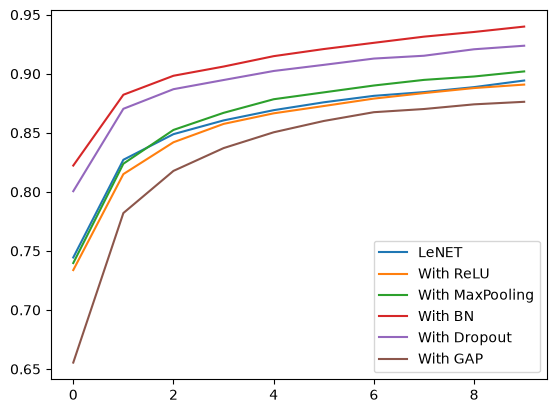

In [32]:
import matplotlib.pyplot as plt

plt.plot(lenet_history.history['accuracy'], label = 'LeNET')
plt.plot(relu_history.history['accuracy'], label = "With ReLU")
plt.plot(max_history.history['accuracy'], label = "With MaxPooling")
plt.plot(bn_history.history['accuracy'], label = "With BN")
plt.plot(dropout_history.history['accuracy'], label = "With Dropout")
plt.plot(gap_history.history['accuracy'], label = "With GAP")
plt.legend()
plt.show()